In [ ]:
import pandas as pd
from io import BytesIO
print ("Library berhasil di-Imprt")

Library berhasil di-Imprt


In [ ]:

# Upload dataset ke Google Colab
from google.colab import files

uploaded = files.upload()

Saving netflix_titles.csv to netflix_titles (1).csv


In [ ]:
# Mencari file dengan format CSV
file_name = next(
    name for name in uploaded.keys()
    if name.lower().endswith(".csv")
)

In [ ]:
# Membaca file CSV menggunakan Pandas
netflix_df = pd.read_csv(BytesIO(uploaded[file_name]))

print("Dataset berhasil dibaca!")

Dataset berhasil dibaca!


In [ ]:

# Melihat jumlah baris dan kolom
print("Jumlah baris:", netflix_df.shape[0])
print("Jumlah kolom:", netflix_df.shape[1])

Jumlah baris: 8807
Jumlah kolom: 12


In [ ]:

# Menampilkan 5 baris pertama
netflix_df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [ ]:

# Melihat informasi setiap kolom
netflix_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [ ]:
#Checkpoint Step 1

#Setelah menjalankan semua kode Step 1, kamu seharusnya sudah mengetahui:
#- Berapa banyak baris dan kolom.
#- Bagaimana bentuk tabel dataset.
#- Apa saja nama kolomnya.
#- Apa tipe data setiap kolom.

In [ ]:

# Menghitung jumlah data kosong setiap kolom
missing_values = netflix_df.isnull().sum()

print(missing_values)

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64


In [ ]:

# Menghitung persentase missing values
missing_percentage = (
    netflix_df.isnull().sum() / len(netflix_df)
) * 100



In [ ]:
# Membuat tabel ringkasan
missing_summary = pd.DataFrame({
    "Missing Values": netflix_df.isnull().sum(),
    "Percentage (%)": missing_percentage.round(2)
})

display(missing_summary)

,Missing Values,Percentage (%)
show_id,0,0.00
type,0,0.00
title,0,0.00
director,2634,29.91
cast,825,9.37
country,831,9.44
date_added,10,0.11
release_year,0,0.00
rating,4,0.05
duration,3,0.03


In [ ]:

# Memeriksa jumlah baris duplikat secara keseluruhan
print(
    "Duplicate rows:",
    netflix_df.duplicated().sum()
)

Duplicate rows: 0


In [ ]:

# Memeriksa duplikasi berdasarkan ID konten
print(
    "Duplicate show_id:",
    netflix_df["show_id"].duplicated().sum()
)

Duplicate show_id: 0


In [ ]:

# Memeriksa tipe data setiap kolom
netflix_df.dtypes

,0
show_id,object
type,object
title,object
director,object
cast,object
country,object
date_added,object
release_year,int64
rating,object
duration,object


In [ ]:

# Membuat salinan dataset
netflix_clean = netflix_df.copy()

print("Salinan dataset berhasil dibuat!")

Salinan dataset berhasil dibuat!


In [ ]:

# Menghapus baris yang tidak memiliki show_id
netflix_clean = netflix_clean.dropna(
    subset=["show_id"]
)

print("Sisa baris:", len(netflix_clean))

Sisa baris: 8807


In [ ]:

# Menghapus duplikasi berdasarkan show_id
netflix_clean = netflix_clean.drop_duplicates(
    subset=["show_id"],
    keep="first"
)

print("Sisa baris setelah menghapus duplikasi:", len(netflix_clean))

Sisa baris setelah menghapus duplikasi: 8807


In [ ]:

# Merapikan spasi pada kolom teks
text_columns = netflix_clean.select_dtypes(
    include="object"
).columns

for column in text_columns:
    netflix_clean[column] = (
        netflix_clean[column]
        .str.strip()
        .replace("", pd.NA)
    )

print("Teks berhasil dirapikan!")

Teks berhasil dirapikan!


In [ ]:

# Mengubah date_added menjadi format tanggal
netflix_clean["date_added"] = pd.to_datetime(
    netflix_clean["date_added"],
    format="%B %d, %Y",
    errors="coerce"
)

# Memeriksa hasilnya
print(netflix_clean["date_added"].dtype)

datetime64[ns]


In [ ]:

# Memeriksa hasil akhir cleaning
print("Jumlah baris:", netflix_clean.shape[0])
print("Jumlah kolom:", netflix_clean.shape[1])

print(
    "Duplicate show_id:",
    netflix_clean["show_id"].duplicated().sum()
)

display(netflix_clean.head())

Jumlah baris: 8807
Jumlah kolom: 12
Duplicate show_id: 0


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [ ]:

# Ringkasan missing values setelah cleaning
display(
    netflix_clean.isnull().sum().to_frame(
        name="Missing Values After Cleaning"
    )
)

,Missing Values After Cleaning
show_id,0
type,0
title,0
director,2634
cast,825
country,831
date_added,10
release_year,0
rating,4
duration,3


In [ ]:

import matplotlib.pyplot as plt

print("Library visualisasi berhasil di-import!")

Library visualisasi berhasil di-import!


In [ ]:

# Menghitung jumlah konten berdasarkan type
content_distribution = (
    netflix_clean["type"]
    .value_counts()
)

display(content_distribution)

,count
type,
Movie,6131
TV Show,2676


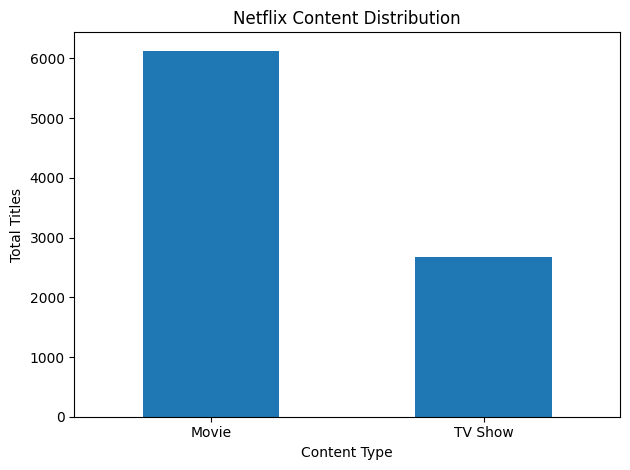

In [ ]:

# Membuat bar chart
content_distribution.plot(
    kind="bar",
    title="Netflix Content Distribution",
    xlabel="Content Type",
    ylabel="Total Titles"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:

# Mengambil kolom genre
genre_data = netflix_clean["listed_in"].dropna()

# Memisahkan setiap genre berdasarkan koma
genre_list = genre_data.str.split(",")

# Mengubah daftar genre menjadi satu kolom
all_genres = genre_list.explode()

# Menghapus spasi di awal dan akhir
all_genres = all_genres.str.strip()

# Menghitung 10 genre terbanyak
top_10_genres = all_genres.value_counts().head(10)

display(top_10_genres)

,count
listed_in,
International Movies,2752
Dramas,2427
Comedies,1674
International TV Shows,1351
Documentaries,869
Action & Adventure,859
TV Dramas,763
Independent Movies,756
Children & Family Movies,641


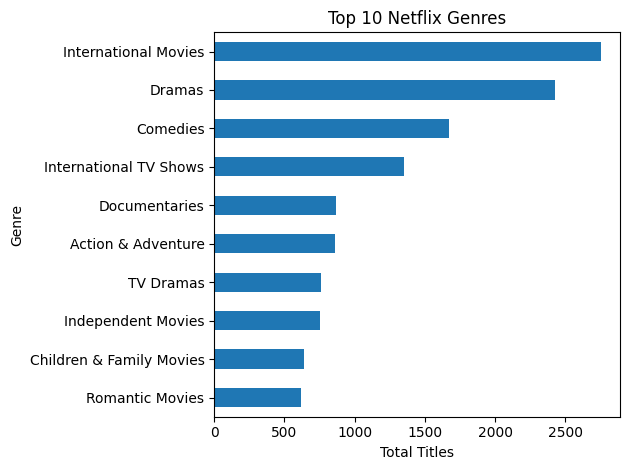

In [ ]:

# Membuat grafik Top 10 Genre
top_10_genres.sort_values().plot(
    kind="barh",
    title="Top 10 Netflix Genres",
    xlabel="Total Titles",
    ylabel="Genre"
)

plt.tight_layout()
plt.show()

In [ ]:

# Mengambil data yang memiliki tanggal penambahan
date_data = netflix_clean.dropna(
    subset=["date_added"]
).copy()

# Mengambil tahun dari date_added
date_data["year_added"] = (
    date_data["date_added"].dt.year
)

# Menghitung jumlah konten per tahun
content_growth = (
    date_data.groupby("year_added")["show_id"]
    .count()
    .sort_index()
)

display(content_growth)

,show_id
year_added,
2008,2
2009,2
2010,1
2011,13
2012,3
2013,11
2014,24
2015,82
2016,429


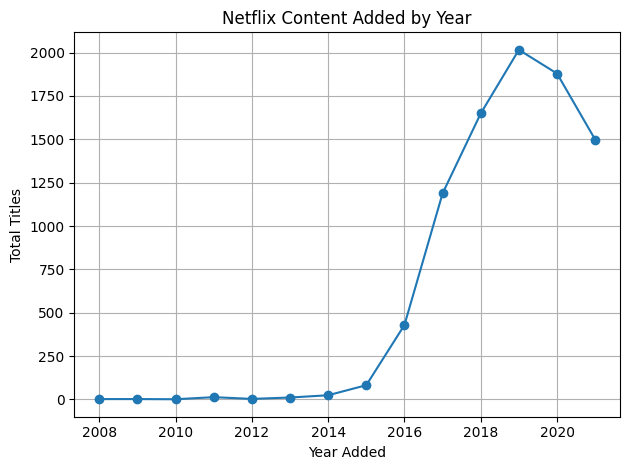

In [ ]:

# Membuat grafik tren penambahan konten
content_growth.plot(
    kind="line",
    marker="o",
    title="Netflix Content Added by Year",
    xlabel="Year Added",
    ylabel="Total Titles"
)

plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:

import csv
import pandas as pd


In [ ]:

# Menyimpan ulang clean dataset dengan format CSV standar

netflix_clean.to_csv(
    "netflix_titles_clean_fixed.csv",
    index=False,
    encoding="utf-8",
    quoting=csv.QUOTE_ALL,
    quotechar='"',
    doublequote=True
)

print("CSV berhasil diperbaiki dan disimpan!")


CSV berhasil diperbaiki dan disimpan!


In [ ]:

# Menyimpan dataset yang sudah dibersihkan
netflix_clean.to_csv(
    "netflix_titles_clean_fixed.csv",
    index=False
)

print("Clean dataset berhasil disimpan!")

Clean dataset berhasil disimpan!


In [ ]:

# Download clean dataset
from google.colab import files

files.download("netflix_titles_clean_fixed.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print("Jumlah data asli:", netflix_df.shape)
print("Jumlah data bersih:", netflix_clean.shape)

print("Kolom dataset:")
print(netflix_clean.columns.tolist())

Jumlah data asli: (8807, 12)
Jumlah data bersih: (8807, 12)
Kolom dataset:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']


In [ ]:
netflix_clean.to_csv(
    "netflix_titles_clean_test.csv",
    index=False,
    encoding="utf-8"
)

print("File berhasil disimpan!")

File berhasil disimpan!


In [ ]:
test_df = pd.read_csv(
    "netflix_titles_clean_test.csv"
)

print("Jumlah baris:", test_df.shape[0])
print("Jumlah kolom:", test_df.shape[1])

display(test_df.head())

Jumlah baris: 8807
Jumlah kolom: 12


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [ ]:
print("netflix_df tersedia:", "netflix_df" in globals())
print("netflix_clean tersedia:", "netflix_clean" in globals())

netflix_df tersedia: True
netflix_clean tersedia: True


In [ ]:
# Mengubah DataFrame menjadi file Parquet
netflix_clean.to_parquet(
    "netflix_titles_clean.parquet",
    index=False
)

print("File Parquet berhasil dibuat!")

File Parquet berhasil dibuat!


In [ ]:
# Download clean dataset
from google.colab import files

files.download("netflix_titles_clean.parquet")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>